In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_path = "../data/raw/train.csv"
test_path = "../data/raw/test.csv"


In [3]:
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)


C:\Users\hp\AppData\Local\Temp\ipykernel_24772\374630687.py:1: DtypeWarning: Columns (4: t000_chest_ecg_1, 5: t000_chest_ecg_2, 6: t000_ankle_acc_x, 8: t000_ankle_acc_z, 11: t000_ankle_gyro_z, 13: t000_ankle_mag_y, 15: t000_arm_acc_x, 16: t000_arm_acc_y, 17: t000_arm_acc_z, 18: t000_arm_gyro_x, 19: t000_arm_gyro_y, 20: t000_arm_gyro_z, 22: t000_arm_mag_y, 23: t000_arm_mag_z, 27: t001_chest_ecg_1, 29: t001_ankle_acc_x, 30: t001_ankle_acc_y, 31: t001_ankle_acc_z, 32: t001_ankle_gyro_x, 34: t001_ankle_gyro_z, 35: t001_ankle_mag_x, 36: t001_ankle_mag_y, 38: t001_arm_acc_x, 40: t001_arm_acc_z, 41: t001_arm_gyro_x, 42: t001_arm_gyro_y, 44: t001_arm_mag_x, 49: t002_chest_acc_z, 51: t002_chest_ecg_2, 52: t002_ankle_acc_x, 55: t002_ankle_gyro_x, 56: t002_ankle_gyro_y, 57: t002_ankle_gyro_z, 64: t002_arm_gyro_x, 66: t002_arm_gyro_z, 68: t002_arm_mag_y, 73: t003_chest_ecg_1, 76: t003_ankle_acc_y, 80: t003_ankle_gyro_z, 81: t003_ankle_mag_x, 82: t003_ankle_mag_y, 83: t003_ankle_mag_z, 84: t003_arm

In [4]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (679, 5752)
Test shape: (403, 5751)


In [5]:
train.head()

,id,t000_chest_acc_x,t000_chest_acc_y,t000_chest_acc_z,t000_chest_ecg_1,t000_chest_ecg_2,t000_ankle_acc_x,t000_ankle_acc_y,t000_ankle_acc_z,t000_ankle_gyro_x,...,t249_arm_acc_x,t249_arm_acc_y,t249_arm_acc_z,t249_arm_gyro_x,t249_arm_gyro_y,t249_arm_gyro_z,t249_arm_mag_x,t249_arm_mag_y,t249_arm_mag_z,target
0,TR000349,-8.8814001,NaN,-5.8944001,0.41025999,0.24699,1.2701,-10.455,NaN,0.39517999,...,3.0706,"-7,33",5.7584,NaN,-0.31828001,-4.6789072878774505,NaN,NaN,-11.285,cycling
1,TR000004,-4.1293998,-0.095922999,0.41242,9999,-0.38514,0.20474,-7.0381999,-0.84986001,0.31354001,...,-2.8387001,-0.65824997,45.54446345970478,-0.73922002,-0.52566999,0.61852998,3.5193,10.82,-39.749001,jump_front_back
2,TR000165,-9.8023996,-1.2951,-1.506,-0.058607999,-0.016744999,0.97938,-60.44825508484209,1.6356,0.32839,...,-1.6627001,-9.0820999,2.7855,-0.080392003,NaN,0.97197998,NaN,1.4479001,-0.74339002,standing
3,TR000592,3.1004,NaN,-0.070830002,-0.48142001,0.73679,9.5712,-3.5511999,-5.6131001,NaN,...,-1.9577,NaN,2.7560999,-1.0294,-0.15195,0.18966,-26.232,NaN,NaN,jogging
4,TR000392,-6.8698001,NaN,-1.0899,NaN,1.2098,2.2173,-8.8645,2.6623001,-0.23377,...,-1.9680001,-66.33279026895241,0.34283999,0.31569001,-0.94867003,-0.47628999,-6.2384,4.5226998,46.761002,knees_bending


In [6]:
print("Total columns:", len(train.columns))


Total columns: 5752


In [7]:
print("First 10 columns:")
print(train.columns[:10].tolist())


First 10 columns:
['id', 't000_chest_acc_x', 't000_chest_acc_y', 't000_chest_acc_z', 't000_chest_ecg_1', 't000_chest_ecg_2', 't000_ankle_acc_x', 't000_ankle_acc_y', 't000_ankle_acc_z', 't000_ankle_gyro_x']


In [9]:
print("Last 10 columns:")
print(train.columns[-10:].tolist())

Last 10 columns:
['t249_arm_acc_x', 't249_arm_acc_y', 't249_arm_acc_z', 't249_arm_gyro_x', 't249_arm_gyro_y', 't249_arm_gyro_z', 't249_arm_mag_x', 't249_arm_mag_y', 't249_arm_mag_z', 'target']


In [10]:
train['target'].value_counts()

target
cycling            67
jogging            66
lying              66
walking            63
running            61
standing           59
sitting            59
climbing_stairs    56
knees_bending      55
arm_elevation      55
waist_bends        53
jump_front_back    19
Name: count, dtype: int64

In [11]:
missing = train.isnull().sum()

print("Total missing values:", missing.sum())
print("Columns containing missing values:", (missing > 0).sum())

Total missing values: 429835
Columns containing missing values: 5750


In [12]:
missing[missing > 0].sort_values(ascending=False).head(15)

t059_ankle_gyro_z    85
t175_chest_ecg_1     85
t249_arm_gyro_z      84
t031_arm_mag_x       84
t054_arm_acc_x       84
t081_arm_mag_z       84
t000_arm_mag_z       83
t047_chest_ecg_2     83
t146_arm_gyro_x      83
t151_ankle_mag_x     83
t108_arm_gyro_z      83
t182_ankle_gyro_z    83
t165_ankle_mag_y     83
t247_chest_ecg_2     83
t095_ankle_acc_z     83
dtype: int64

In [13]:
train_missing = train.drop(columns=['id', 'target']).isnull().sum()
test_missing = test.drop(columns=['id']).isnull().sum()

print("Train missing:", train_missing.sum())
print("Test missing:", test_missing.sum())

Train missing: 429835
Test missing: 0


In [15]:
train_missing.describe()


count    5750.000000
mean       74.753913
std         2.745695
min        66.000000
25%        73.000000
50%        75.000000
75%        77.000000
max        85.000000
dtype: float64

In [16]:
train_missing_percent = (train_missing / len(train)) * 100

train_missing_percent.describe()

count    5750.000000
mean       11.009413
std         0.404373
min         9.720177
25%        10.751105
50%        11.045655
75%        11.340206
max        12.518409
dtype: float64

In [17]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 5


In [18]:
print("Duplicate train IDs:", train['id'].duplicated().sum())
print("Duplicate test IDs:", test['id'].duplicated().sum())

Duplicate train IDs: 44
Duplicate test IDs: 0


In [19]:
duplicate_ids = train[train['id'].duplicated(keep=False)]

print("Rows with duplicate IDs:", len(duplicate_ids))
print("Unique duplicated IDs:", duplicate_ids['id'].nunique())

duplicate_ids.sort_values('id').head(10)

Rows with duplicate IDs: 88
Unique duplicated IDs: 44


,id,t000_chest_acc_x,t000_chest_acc_y,t000_chest_acc_z,t000_chest_ecg_1,t000_chest_ecg_2,t000_ankle_acc_x,t000_ankle_acc_y,t000_ankle_acc_z,t000_ankle_gyro_x,...,t249_arm_acc_x,t249_arm_acc_y,t249_arm_acc_z,t249_arm_gyro_x,t249_arm_gyro_y,t249_arm_gyro_z,t249_arm_mag_x,t249_arm_mag_y,t249_arm_mag_z,target
625,TR000032,-7.4836998,0.95336002,-44.566948612162086,-0.083726,-0.066981003,-0.89184999,-9.5516996,1.2635,0.23932999,...,NaN,-14.068,0.16116001,0.62744999,-0.95893002,-0.12716,2.9524,7.9917998,3.5892,knees_bending
146,TR000032,-7.4836998,0.95336002,-44.566948612162086,-0.083725996,-0.066981003,-0.89184999,-9.5516996,1.2635,0.23932999,...,NaN,-14.068,0.16116001,0.62744999,-0.95893002,-0.12716,2.9524,7.9917998,3.5892,knees_bending
178,TR000049,2.7520001,-0.72972,-0.034095,-0.65306002,NaN,6.4183998,-12.193,-65.99112257754942,-0.1039,...,-64.22582241468074,NaN,-3.6178999,-0.99607998,-0.29774001,-0.030172,-9.5785999,11.615,-27.745001,jogging
304,TR000049,2.7520001,-0.72972,-0.034095,-0.65306002,NaN,6.4183998,-12.193,-65.99112257754942,-0.1039,...,-64.22582241468074,NaN,-3.6178999,-0.99607998,-0.29774,-0.030172,-9.5785999,11.615,-27.745001,jogging
542,TR000051,4.5219998,NaN,"0,34",0.66143,0.26374,NaN,-19.148001,22.819,NaN,...,11.368,-18.631001,-6.0565,-0.58431,NaN,NaN,NaN,119.57,-329.69,running
429,TR000051,4.5219998,NaN,"0,34",0.66143,0.26374,NaN,-19.148001,22.819,NaN,...,11.368,-18.631001,-6.0565,-0.58431,NaN,NaN,NaN,119.57,-329.69,running
678,TR000055,-7.0222998,-1.4083,-1.5477999,0.73679,-0.41863,0.77641,NaN,64.752704,4.27057025761956,...,-0.66144001,-9.0593,3.0679,-0.94313997,NaN,0.125,-26.849001,-9.8694,-15.601,climbing_stairs
447,TR000055,-7.0222998,-1.4083,-1.5477999,0.73679,-0.41863,0.77640998,NaN,64.75270449900452,4.27057025761956,...,-0.66144001,-9.0593004,3.0678999,-0.94313997,NaN,0.125,-26.849001,-9.8694,-15.601,climbing_stairs
198,TR000061,-8.6838999,0.35477999,-3.7574999,-0.012559,0.012559,-0.75839001,-9.8209,1.0743001,0.25602999,...,NaN,-9.6890001,0.098883003,0.53921998,-0.99383998,0.24138001,-2.0983,"5,61",NaN,knees_bending
324,TR000061,-8.6838999,0.35477999,-3.7574999,-0.012559,0.012559,-0.75839001,-9.8209,1.0743001,0.25602999,...,NaN,-9.6890001,0.098883003,0.53921998,-0.99384,0.24138001,-2.0983,"5,61",NaN,knees_bending


In [20]:
train.groupby('id')['target'].nunique().value_counts()

target
1    635
Name: count, dtype: int64

In [21]:
print("Exact duplicate rows:", train.duplicated().sum())

Exact duplicate rows: 5


In [22]:
train['id'].value_counts().value_counts().sort_index()

count
1    591
2     44
Name: count, dtype: int64

In [25]:
duplicate_ids.sort_values('id')[['id', 'target']].head(20)

,id,target
625,TR000032,knees_bending
146,TR000032,knees_bending
178,TR000049,jogging
304,TR000049,jogging
542,TR000051,running
429,TR000051,running
678,TR000055,climbing_stairs
447,TR000055,climbing_stairs
198,TR000061,knees_bending
324,TR000061,knees_bending


In [26]:
sensor_cols = train.columns.drop(['id', 'target'])

duplicate_ids.groupby('id')[sensor_cols].nunique().max(axis=1).value_counts()

2    39
1     5
Name: count, dtype: int64

In [27]:
print("Exact duplicate rows:", train.duplicated().sum())

Exact duplicate rows: 5


In [28]:
print("Exact duplicate rows:", train.duplicated().sum())

print("Duplicate IDs:", train['id'].duplicated().sum())

print("Unique IDs:", train['id'].nunique())

Exact duplicate rows: 5
Duplicate IDs: 44
Unique IDs: 635


In [29]:
exact_duplicates = train[train.duplicated(keep=False)]

exact_duplicates.sort_values('id')[['id', 'target']]

,id,target
397,TR000110,lying
501,TR000110,lying
575,TR000413,cycling
594,TR000413,cycling
260,TR000444,cycling
365,TR000444,cycling
390,TR000454,walking
391,TR000454,walking
269,TR000525,jogging
284,TR000525,jogging


In [30]:
sensor_cols = train.drop(columns=['id', 'target'])

nunique_features = sensor_cols.nunique()

constant_features = nunique_features[nunique_features == 1]

print("Constant features:", len(constant_features))

Constant features: 0


In [31]:
nunique_features.sort_values().head(20)

t048_chest_ecg_2    238
t075_chest_ecg_2    242
t171_chest_ecg_2    242
t220_chest_ecg_2    245
t144_chest_ecg_2    245
t148_chest_ecg_2    246
t070_chest_ecg_2    248
t101_chest_ecg_2    249
t232_chest_ecg_2    249
t114_chest_ecg_2    249
t071_chest_ecg_2    250
t217_chest_ecg_2    251
t026_chest_ecg_2    251
t182_chest_ecg_2    252
t226_chest_ecg_2    252
t185_chest_ecg_2    252
t083_chest_ecg_2    252
t103_chest_ecg_2    253
t121_chest_ecg_2    253
t110_chest_ecg_2    253
dtype: int64

In [34]:
sensor_cols = train.drop(columns=['id', 'target'])


In [36]:
sensor_cols.dtypes.value_counts()

object    3155
str       2595
Name: count, dtype: int64

In [37]:
print(sensor_cols.iloc[:, 0].head(10))
print(sensor_cols.iloc[:, 0].dtype)

0    -8.8814001
1    -4.1293998
2    -9.8023996
3        3.1004
4    -6.8698001
5    -8.7392998
6       -21.687
7    -9.6583004
8           NaN
9    -9.8112001
Name: t000_chest_acc_x, dtype: str
str


In [38]:
print(train['t000_chest_acc_x'].map(type).value_counts())

t000_chest_acc_x
<class 'str'>      609
<class 'float'>     70
Name: count, dtype: int64


In [39]:
print(train['t000_chest_acc_x'].isna().sum())

70


In [40]:
sensor_numeric = sensor_cols.apply(pd.to_numeric, errors='coerce')

print(sensor_numeric.dtypes.value_counts())
print("NaN before:", sensor_cols.isna().sum().sum())
print("NaN after:", sensor_numeric.isna().sum().sum())

float64    5750
Name: count, dtype: int64
NaN before: 429835
NaN after: 516835


In [41]:
invalid_mask = (
    sensor_cols.notna() &
    sensor_numeric.isna()
)

print("Total invalid values:", invalid_mask.sum().sum())

invalid_counts = invalid_mask.sum(axis=0)
print(invalid_counts.sort_values(ascending=False).head(10))

Total invalid values: 87000
t218_arm_gyro_y      29
t149_ankle_acc_x     27
t006_arm_gyro_y      27
t070_ankle_mag_y     26
t158_ankle_acc_z     26
t067_arm_mag_y       25
t101_arm_gyro_y      25
t159_chest_ecg_2     25
t047_arm_gyro_x      25
t209_ankle_gyro_z    25
dtype: int64


In [42]:
col = invalid_counts.idxmax()

print("Column:", col)
print(sensor_cols.loc[invalid_mask[col], col].value_counts().head(15))

Column: t218_arm_gyro_y
t218_arm_gyro_y
-          7
unknown    3
-5,88      2
?          2
0,90       1
0,39       1
-0,88      1
-1,07      1
-0,59      1
0,20       1
-0,06      1
-0,85      1
-0,60      1
-0,94      1
-0,57      1
Name: count, dtype: int64


In [44]:
invalid_values = sensor_cols.where(invalid_mask).stack()

print(invalid_values.value_counts().head(20))

-          11949
unknown    11933
?          11827
9999,00     2550
0,36         363
0,37         314
0,55         300
0,18         273
-0,72        271
0,01         262
-0,15        244
-0,01        241
-0,36        239
0,19         229
0,00         222
0,73         211
0,35         206
-0,10        205
-0,08        202
0,17         202
Name: count, dtype: int64


In [45]:
sentinel_count = (
    sensor_cols.astype("string") == "9999,00"
).sum()

print("Total:", sentinel_count.sum())
print(sentinel_count[sentinel_count > 0].sort_values(ascending=False).head(15))


Total: 2550
t077_chest_acc_z     5
t011_arm_mag_x       5
t193_ankle_gyro_y    5
t173_chest_ecg_1     4
t219_ankle_mag_z     4
t175_chest_acc_x     4
t206_arm_acc_y       4
t033_arm_gyro_y      4
t024_ankle_mag_x     4
t094_ankle_mag_y     4
t034_chest_acc_x     4
t188_arm_gyro_x      4
t054_chest_acc_y     3
t079_arm_gyro_z      3
t054_arm_gyro_y      3
dtype: Int64


In [48]:
for col in ['t077_chest_acc_z', 't011_arm_mag_x', 't193_ankle_gyro_y']:
    print("\nColumn:", col)
    print(sensor_cols[col].value_counts().head(10))


Column: t077_chest_acc_z
t077_chest_acc_z
9999                  25
44.55692607872108     14
-46.78960303598092    13
9999,00                5
unknown                5
-                      3
-16.389                2
-5.8143001             2
-3.9693999             2
-10.301                2
Name: count, dtype: int64

Column: t011_arm_mag_x
t011_arm_mag_x
9999                  26
337.1606178259788     15
-334.6272908944216     8
9999,00                5
0.36262                5
?                      5
0.3644                 5
0.36443999             4
0.36258999             4
0.18126                3
Name: count, dtype: int64

Column: t193_ankle_gyro_y
t193_ankle_gyro_y
9999                   27
-4.9484657611945915    14
3.9245190275123862     13
9999,00                 5
-0.71670002             5
-0.85553002             5
-0.87805003             5
-0.57410997             5
-0.58537                5
0.94371003              5
Name: count, dtype: int64


In [49]:
train_clean = train.copy()
test_clean = test.copy()

feature_cols = train.columns.drop(['id', 'target'])

print(train_clean.shape)
print(test_clean.shape)

(679, 5752)
(403, 5751)


In [50]:
missing_tokens = ['-', 'unknown', '?', '']

for df in [train_clean, test_clean]:
    df[feature_cols] = df[feature_cols].astype('string')

    df[feature_cols] = df[feature_cols].apply(
        lambda col: col.str.strip()
    )

    df[feature_cols] = df[feature_cols].replace(
        missing_tokens, np.nan
    )

In [51]:
for df in [train_clean, test_clean]:
    df[feature_cols] = df[feature_cols].apply(
        lambda col: col.str.replace(',', '.', regex=False)
    )

In [52]:
for df in [train_clean, test_clean]:
    df[feature_cols] = df[feature_cols].apply(
        pd.to_numeric, errors='coerce'
    )

In [53]:
for df in [train_clean, test_clean]:
    df[feature_cols] = df[feature_cols].replace(9999, np.nan)

In [54]:
print("Train dtypes:")
print(train_clean[feature_cols].dtypes.value_counts())

print("\nTrain missing values:")
print(train_clean[feature_cols].isna().sum().sum())

print("\nTest missing values:")
print(test_clean[feature_cols].isna().sum().sum())

Train dtypes:
Float64    5750
Name: count, dtype: int64

Train missing values:
638842

Test missing values:
0


In [55]:
row_missing = train_clean[feature_cols].isna().sum(axis=1)

print(row_missing.describe())

count     679.000000
mean      940.857143
std        27.234834
min       866.000000
25%       922.000000
50%       941.000000
75%       960.000000
max      1023.000000
dtype: float64


In [56]:
channel_missing = train_clean[feature_cols].isna().sum()

print(channel_missing.describe())
print("\nMost missing features:")
print(channel_missing.sort_values(ascending=False).head(10))

print("\nLeast missing features:")
print(channel_missing.sort_values().head(10))

count    5750.000000
mean      111.102957
std         3.225589
min        99.000000
25%       109.000000
50%       111.000000
75%       113.000000
max       124.000000
dtype: float64

Most missing features:
t186_ankle_acc_y     124
t170_chest_ecg_2     122
t185_ankle_acc_z     121
t227_arm_gyro_x      121
t199_chest_acc_z     121
t140_chest_acc_y     121
t027_ankle_mag_z     121
t187_arm_acc_y       121
t213_ankle_gyro_y    121
t249_arm_gyro_z      121
dtype: int64

Least missing features:
t127_ankle_mag_z     99
t047_chest_ecg_1     99
t237_ankle_mag_x    100
t176_chest_acc_z    100
t193_chest_ecg_2    100
t199_arm_acc_x      101
t185_arm_gyro_x     101
t015_arm_mag_x      101
t111_arm_mag_y      101
t129_ankle_mag_x    102
dtype: int64


In [57]:
for name, df in [('Train', train), ('Test', test)]:
    sensor = df.drop(columns=['id', 'target'], errors='ignore')
    sensor = sensor.astype('string').apply(
        lambda col: col.str.strip()
    )

    count_9999 = sensor.isin(['9999', '9999,00']).sum().sum()

    print(name, "9999 occurrences:", count_9999)

Train 9999 occurrences: 161322
Test 9999 occurrences: 0


In [58]:
sensor_raw = train.drop(columns=['id', 'target']).astype('string')

sensor_raw = sensor_raw.apply(
    lambda col: col.str.strip()
)

mask_9999 = sensor_raw.isin(['9999', '9999,00'])

print("Affected features:", (mask_9999.sum() > 0).sum())

print("\nTop affected features:")
print(mask_9999.sum().sort_values(ascending=False).head(15))

print("\nAffected rows:")
print((mask_9999.sum(axis=1) > 0).sum())

Affected features: 5750

Top affected features:
t137_ankle_gyro_x    39
t101_arm_gyro_x      38
t168_arm_gyro_z      37
t167_chest_ecg_2     37
t199_chest_ecg_2     37
t062_arm_acc_z       37
t237_ankle_acc_x     37
t154_ankle_gyro_z    37
t225_arm_gyro_z      37
t108_arm_acc_z       36
t003_arm_gyro_y      36
t096_ankle_gyro_y    36
t016_arm_acc_z       36
t094_ankle_acc_z     36
t049_arm_gyro_x      36
dtype: int64

Affected rows:
679


In [59]:
print("Exact duplicate rows:", train_clean.duplicated().sum())

print("Duplicate IDs:", train_clean['id'].duplicated().sum())

print("Unique IDs:", train_clean['id'].nunique())

Exact duplicate rows: 44
Duplicate IDs: 44
Unique IDs: 635


In [60]:
duplicate_rows = train_clean[
    train_clean.duplicated(subset=['id'], keep=False)
].sort_values('id')

print(duplicate_rows[['id', 'target']].head(20))

           id           target
625  TR000032    knees_bending
146  TR000032    knees_bending
178  TR000049          jogging
304  TR000049          jogging
542  TR000051          running
429  TR000051          running
678  TR000055  climbing_stairs
447  TR000055  climbing_stairs
198  TR000061    knees_bending
324  TR000061    knees_bending
348  TR000090      waist_bends
220  TR000090      waist_bends
504  TR000099          jogging
73   TR000099          jogging
501  TR000110            lying
397  TR000110            lying
261  TR000126          jogging
39   TR000126          jogging
294  TR000130            lying
53   TR000130            lying


In [61]:
print(
    duplicate_rows.groupby('id')['target']
    .nunique()
    .value_counts()
)

target
1    44
Name: count, dtype: int64


In [62]:
sample_id = duplicate_rows['id'].iloc[0]

print(train[train['id'] == sample_id].iloc[:, :12].to_string(index=False))
print(train_clean[train_clean['id'] == sample_id].iloc[:, :12].to_string(index=False))

      id t000_chest_acc_x t000_chest_acc_y    t000_chest_acc_z t000_chest_ecg_1 t000_chest_ecg_2 t000_ankle_acc_x t000_ankle_acc_y t000_ankle_acc_z t000_ankle_gyro_x t000_ankle_gyro_y t000_ankle_gyro_z
TR000032       -7.4836998       0.95336002 -44.566948612162086     -0.083725996     -0.066981003      -0.89184999       -9.5516996           1.2635        0.23932999       -0.87242001          -0.55599
TR000032       -7.4836998       0.95336002 -44.566948612162086        -0.083726     -0.066981003      -0.89184999       -9.5516996           1.2635        0.23932999       -0.87242001       -0.55598998
      id  t000_chest_acc_x  t000_chest_acc_y  t000_chest_acc_z  t000_chest_ecg_1  t000_chest_ecg_2  t000_ankle_acc_x  t000_ankle_acc_y  t000_ankle_acc_z  t000_ankle_gyro_x  t000_ankle_gyro_y  t000_ankle_gyro_z
TR000032           -7.4837           0.95336        -44.566949         -0.083726         -0.066981          -0.89185           -9.5517            1.2635            0.23933           -0

In [63]:
dup_ids = train.loc[
    train['id'].duplicated(keep=False), 'id'
].unique()

different_columns = {}

for sample_id in dup_ids:
    group = train[train['id'] == sample_id]
    sensor_data = group.drop(columns=['id', 'target'])

    different_columns[sample_id] = (
        sensor_data.nunique(dropna=False) > 1
    ).sum()

print(pd.Series(different_columns).describe())

print("\nIDs with different raw sensor readings:")
print(pd.Series(different_columns).loc[
    lambda x: x > 0
].head(15))

count      44.000000
mean      523.977273
std       467.549599
min         0.000000
25%       449.000000
50%       458.500000
75%       469.750000
max      2162.000000
dtype: float64

IDs with different raw sensor readings:
TR000126    485
TR000245    462
TR000583    465
TR000489    478
TR000196    501
TR000130    491
TR000099    472
TR000342    474
TR000623    468
TR000403    463
TR000322    467
TR000461    455
TR000523    478
TR000410    450
TR000032    457
dtype: int64


In [64]:
sample_id = 'TR000032'

raw_group = train[train['id'] == sample_id]
clean_group = train_clean[train_clean['id'] == sample_id]

diff_cols = raw_group.drop(
    columns=['id', 'target']
).nunique(dropna=False)

diff_cols = diff_cols[diff_cols > 1].index

for col in diff_cols[:10]:
    print(
        col,
        "| Raw:", raw_group[col].tolist(),
        "| Clean:", clean_group[col].tolist()
    )

t000_chest_ecg_1 | Raw: ['-0.083725996', -0.083725996] | Clean: [-0.083725996, -0.083725996]
t000_ankle_gyro_z | Raw: [-0.55598998, '-0.55598998'] | Clean: [-0.55598998, -0.55598998]
t000_arm_acc_x | Raw: [-1.7249, '-1.7249'] | Clean: [-1.7249, -1.7249]
t001_ankle_gyro_z | Raw: [-0.55598998, '-0.55598998'] | Clean: [-0.55598998, -0.55598998]
t002_chest_acc_z | Raw: [-3.9026999, '-3.9026999'] | Clean: [-3.9026999, -3.9026999]
t002_arm_gyro_x | Raw: ['9999', 9999.0] | Clean: [<NA>, <NA>]
t003_ankle_acc_y | Raw: [-9.5700998, '-9.5700998'] | Clean: [-9.5700998, -9.5700998]
t003_ankle_mag_x | Raw: ['10.139', 10.139] | Clean: [10.139, 10.139]
t003_ankle_mag_y | Raw: ['-5.6059999', -5.6059999] | Clean: [-5.6059999, -5.6059999]
t003_arm_acc_x | Raw: [-2.2544, '-2.2544'] | Clean: [-2.2544, -2.2544]


In [65]:
print("Before:", train_clean.shape)

train_clean = train_clean.drop_duplicates(
    subset=['id'],
    keep='first'
).reset_index(drop=True)

print("After:", train_clean.shape)
print("Remaining duplicate IDs:", train_clean['id'].duplicated().sum())

Before: (679, 5752)
After: (635, 5752)
Remaining duplicate IDs: 0


In [66]:
print(train_clean['target'].value_counts())
print("\nUnique IDs:", train_clean['id'].nunique())

target
lying              60
cycling            59
jogging            59
walking            59
standing           58
sitting            58
running            58
climbing_stairs    54
arm_elevation      54
knees_bending      50
waist_bends        49
jump_front_back    17
Name: count, dtype: int64

Unique IDs: 635


In [68]:

print("Total missing:", train_clean[feature_cols].isna().sum().sum())

missing_percent = (
    train_clean[feature_cols].isna().mean() * 100
)

print("\nMissing percentage:")
print(missing_percent.describe())

print("\nTop 10 missing features:")
print(missing_percent.sort_values(ascending=False).head(10))

row_missing_percent = train_clean[feature_cols].isna().mean(axis=1) * 100

print("\nRow-wise missing percentage:")
print(row_missing_percent.describe())

Total missing: 597320

Missing percentage:
count    5750.000000
mean       16.359329
std         0.327580
min        15.118110
25%        16.062992
50%        16.377953
75%        16.535433
max        17.165354
dtype: float64

Top 10 missing features:
t157_arm_acc_y       17.165354
t137_arm_mag_z       17.165354
t113_ankle_mag_x     17.165354
t085_ankle_gyro_y    17.165354
t191_ankle_gyro_z    17.165354
t015_arm_acc_z       17.165354
t170_ankle_acc_y     17.165354
t193_arm_mag_x       17.165354
t114_arm_mag_z       17.165354
t199_arm_acc_z       17.165354
dtype: float64

Row-wise missing percentage:
count    635.000000
mean      16.359329
std        0.473105
min       15.060870
25%       16.034783
50%       16.365217
75%       16.695652
max       17.791304
dtype: float64


In [69]:
sensor_types = ['chest', 'ankle', 'arm']

for sensor in sensor_types:
    cols = [
        col for col in feature_cols
        if f'_{sensor}_' in col
    ]

    missing = train_clean[cols].isna().mean().mean() * 100

    print(sensor, "missing percentage:", round(missing, 2))

chest missing percentage: 16.35
ankle missing percentage: 16.36
arm missing percentage: 16.37


In [70]:
sample = train_clean.iloc[0]

channel_cols = [
    col for col in feature_cols
    if col.endswith('_chest_acc_x')
]

values = sample[channel_cols]

print(values.isna().sum())
print(values.head(30))

46
t000_chest_acc_x      -8.8814
t001_chest_acc_x         <NA>
t002_chest_acc_x      -9.6809
t003_chest_acc_x       -8.254
t004_chest_acc_x    50.456155
t005_chest_acc_x      -8.0088
t006_chest_acc_x      -8.6168
t007_chest_acc_x      -8.8205
t008_chest_acc_x      -8.7049
t009_chest_acc_x      -8.5778
t010_chest_acc_x      -8.1825
t011_chest_acc_x   -66.599954
t012_chest_acc_x         <NA>
t013_chest_acc_x    -63.47203
t014_chest_acc_x      -7.9592
t015_chest_acc_x       -7.874
t016_chest_acc_x      -7.6845
t017_chest_acc_x         <NA>
t018_chest_acc_x         <NA>
t019_chest_acc_x   -62.875816
t020_chest_acc_x      -9.3505
t021_chest_acc_x      -9.2152
t022_chest_acc_x      -8.9352
t023_chest_acc_x      -8.0258
t024_chest_acc_x      -7.8572
t025_chest_acc_x      -7.6217
t026_chest_acc_x       -6.408
t027_chest_acc_x      -5.5783
t028_chest_acc_x         <NA>
t029_chest_acc_x      -6.9454
Name: 0, dtype: object


In [71]:
missing_mask = values.isna()

groups = missing_mask.ne(missing_mask.shift()).cumsum()

missing_runs = (
    missing_mask.groupby(groups)
    .sum()
)

print("Longest consecutive missing gap:",
      missing_runs.max())

print("\nMissing time steps:")
print(values[missing_mask].index.tolist())

Longest consecutive missing gap: 4

Missing time steps:
['t001_chest_acc_x', 't012_chest_acc_x', 't017_chest_acc_x', 't018_chest_acc_x', 't028_chest_acc_x', 't034_chest_acc_x', 't039_chest_acc_x', 't042_chest_acc_x', 't044_chest_acc_x', 't048_chest_acc_x', 't056_chest_acc_x', 't059_chest_acc_x', 't070_chest_acc_x', 't077_chest_acc_x', 't093_chest_acc_x', 't104_chest_acc_x', 't108_chest_acc_x', 't116_chest_acc_x', 't119_chest_acc_x', 't127_chest_acc_x', 't132_chest_acc_x', 't134_chest_acc_x', 't138_chest_acc_x', 't142_chest_acc_x', 't149_chest_acc_x', 't156_chest_acc_x', 't158_chest_acc_x', 't160_chest_acc_x', 't165_chest_acc_x', 't178_chest_acc_x', 't180_chest_acc_x', 't193_chest_acc_x', 't194_chest_acc_x', 't198_chest_acc_x', 't203_chest_acc_x', 't205_chest_acc_x', 't206_chest_acc_x', 't207_chest_acc_x', 't208_chest_acc_x', 't214_chest_acc_x', 't221_chest_acc_x', 't225_chest_acc_x', 't227_chest_acc_x', 't229_chest_acc_x', 't239_chest_acc_x', 't241_chest_acc_x']


In [72]:
max_gaps = []

for idx in range(len(train_clean)):
    for channel in ['chest_acc_x', 'ankle_acc_x', 'arm_acc_x']:

        cols = [
            c for c in feature_cols
            if c.endswith(channel)
        ]

        row = train_clean.iloc[idx][cols]
        mask = row.isna()

        groups = mask.ne(mask.shift()).cumsum()
        runs = mask.groupby(groups).sum()

        max_gaps.append(runs.max())

print("Overall largest gap:", max(max_gaps))

Overall largest gap: 6


In [73]:
channel = 'chest_acc_x'

cols = [col for col in feature_cols if channel in col]

max_gap = 0

for i in range(len(train_clean)):

    values = train_clean.loc[i, cols].isna().tolist()

    count = 0

    for value in values:
        if value:
            count += 1
            max_gap = max(max_gap, count)
        else:
            count = 0

print("Maximum missing gap:", max_gap)

Maximum missing gap: 6


In [74]:
channel = 'ankle_acc_x'

cols = [col for col in feature_cols if channel in col]

max_gap = 0

for i in range(len(train_clean)):
    values = train_clean.loc[i, cols].isna().tolist()
    count = 0

    for value in values:
        if value:
            count += 1
            max_gap = max(max_gap, count)
        else:
            count = 0

print("Maximum missing gap:", max_gap)

Maximum missing gap: 6


In [75]:
channel = 'arm_acc_x'

cols = [col for col in feature_cols if channel in col]

max_gap = 0

for i in range(len(train_clean)):
    values = train_clean.loc[i, cols].isna().tolist()
    count = 0

    for value in values:
        if value:
            count += 1
            max_gap = max(max_gap, count)
        else:
            count = 0

print("Maximum missing gap:", max_gap)

Maximum missing gap: 6


In [76]:
row_missing = train_clean[feature_cols].isna().sum(axis=1)

print("Maximum missing values:", row_missing.max())
print("Minimum missing values:", row_missing.min())
print("Average missing values:", row_missing.mean())

Maximum missing values: 1023
Minimum missing values: 866
Average missing values: 940.6614173228346


In [77]:
print(train_clean[feature_cols].describe().loc[
    ['min', 'max', 'mean', 'std']
].T.sort_values('max', ascending=False).head(10))

                         min         max       mean         std
t178_arm_mag_z   -962.410392  956.431851   1.496164  234.309106
t179_arm_mag_z       -943.93      937.73  -4.686262  225.643726
t180_arm_mag_z   -930.107543  924.220236  12.470218  225.866035
t177_arm_mag_z   -925.936209  920.147739  -1.665495  225.936518
t181_arm_mag_z   -898.869748  893.527624 -15.737355  213.669684
t143_arm_mag_z   -907.087438  891.757089   4.686297  209.901266
t144_arm_mag_z   -893.772344   876.84452 -12.091337  215.068184
t176_arm_mag_z   -881.081592  874.244352 -11.952994  209.976101
t142_arm_mag_z   -886.075375  873.907291  -6.956501  215.353327
t202_ankle_mag_x -853.870749  865.863626  -9.386737   206.71597


In [78]:
for sensor in ['acc', 'gyro', 'mag', 'ecg']:

    cols = [col for col in feature_cols if f'_{sensor}_' in col]

    print("\n", sensor)
    print("Minimum:", train_clean[cols].min().min())
    print("Maximum:", train_clean[cols].max().max())
    print("Mean:", train_clean[cols].stack().mean())


 acc
Minimum: -72.41244719306209
Maximum: 69.38230087903592
Mean: -2.592085360518181

 gyro
Minimum: -6.1031945443068425
Maximum: 5.821070315704049
Mean: -0.12931797334777428

 mag
Minimum: -962.4103917575974
Maximum: 956.4318507137807
Mean: -0.16087121548973762

 ecg
Minimum: -10.56767014847952
Maximum: 10.575792191987867
Mean: -0.012765081396888717


In [79]:
col = 't178_arm_mag_z'

Q1 = train_clean[col].quantile(0.25)
Q3 = train_clean[col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = train_clean[
    (train_clean[col] < lower) |
    (train_clean[col] > upper)
]

print("Lower:", lower)
print("Upper:", upper)
print("Outliers:", len(outliers))

Lower: -42.599575224999995
Upper: 40.104625375
Outliers: 162


In [80]:
print(outliers[col].sort_values().head(10))

print("\nHighest outliers:")
print(outliers[col].sort_values(ascending=False).head(10))

14    -962.410392
24    -962.410392
58    -962.410392
55    -962.410392
116   -962.410392
192   -962.410392
197   -962.410392
532   -962.410392
568   -962.410392
609   -962.410392
Name: t178_arm_mag_z, dtype: Float64

Highest outliers:
53     956.431851
33     956.431851
52     956.431851
75     956.431851
501    956.431851
518    956.431851
601    956.431851
387    956.431851
530    956.431851
595    956.431851
Name: t178_arm_mag_z, dtype: Float64


In [81]:
print(train_clean[col].value_counts().head(10))

t178_arm_mag_z
 956.431851    14
-962.410392    13
-0.72012        6
-0.35909        5
-1.0793         5
-0.71651        4
-0.35193        3
-0.35915        3
-0.35726        3
-0.35549        3
Name: count, dtype: Int64


In [82]:
outlier_ids = outliers['id']

print(
    train_clean.loc[
        train_clean['id'].isin(outlier_ids), 'target'
    ].value_counts()
)

target
running            46
jogging            30
walking            22
arm_elevation      20
climbing_stairs    14
jump_front_back    10
knees_bending       7
waist_bends         6
sitting             4
lying               3
Name: count, dtype: int64


In [83]:
for t in range(175, 181):
    name = f't{t:03d}_arm_mag_z'

    print(
        name,
        "Min:", train_clean[name].min(),
        "Max:", train_clean[name].max()
    )

t175_arm_mag_z Min: -852.7703995639228 Max: 845.385017332096
t176_arm_mag_z Min: -881.0815924593106 Max: 874.2443519448549
t177_arm_mag_z Min: -925.9362086336121 Max: 920.1477392484655
t178_arm_mag_z Min: -962.4103917575974 Max: 956.4318507137807
t179_arm_mag_z Min: -943.93 Max: 937.73
t180_arm_mag_z Min: -930.107542612857 Max: 924.2202364202093


In [84]:
train_features = train_clean.drop(
    columns=['id', 'target']
).columns

test_features = test.drop(
    columns=['id']
).columns

print("Same features:", train_features.equals(test_features))
print("Train features:", len(train_features))
print("Test features:", len(test_features))

Same features: True
Train features: 5750
Test features: 5750


In [85]:
print("Train missing:", train_clean[feature_cols].isna().sum().sum())

print("Test missing:", test[feature_cols].isna().sum().sum())

Train missing: 597320
Test missing: 0


In [86]:
print(test_clean[feature_cols].dtypes.value_counts())

print("Test missing:",
      test_clean[feature_cols].isna().sum().sum())

print("Train shape:", train_clean.shape)
print("Test shape:", test_clean.shape)

Float64    5750
Name: count, dtype: int64
Test missing: 0
Train shape: (635, 5752)
Test shape: (403, 5751)


In [87]:
print("Original train:", train.shape)
print("Current clean train:", train_clean.shape)

print("Original duplicate IDs:",
      train['id'].duplicated().sum())

print("Clean duplicate IDs:",
      train_clean['id'].duplicated().sum())

Original train: (679, 5752)
Current clean train: (635, 5752)
Original duplicate IDs: 44
Clean duplicate IDs: 0


In [88]:
dup_ids = train['id'][train['id'].duplicated()].unique()

for sample_id in dup_ids[:5]:

    raw = train[train['id'] == sample_id]
    cleaned = train_clean[train_clean['id'] == sample_id]

    print(sample_id, "Original:", len(raw),
          "Cleaned:", len(cleaned))

TR000322 Original: 2 Cleaned: 1
TR000583 Original: 2 Cleaned: 1
TR000403 Original: 2 Cleaned: 1
TR000461 Original: 2 Cleaned: 1
TR000126 Original: 2 Cleaned: 1


In [89]:
for sample_id in dup_ids:

    raw = train[train['id'] == sample_id]
    raw = raw.drop(columns=['id', 'target'])

    raw = raw.apply(
        lambda col: pd.to_numeric(
            col.astype('string').str.replace(',', '.', regex=False),
            errors='coerce'
        )
    )

    if raw.iloc[0].equals(raw.iloc[1]):
        print(sample_id, "Identical")
    else:
        print(sample_id, "Different")

TR000322 Identical
TR000583 Identical
TR000403 Identical
TR000461 Identical
TR000126 Identical
TR000525 Identical
TR000130 Identical
TR000049 Identical
TR000061 Identical
TR000090 Identical
TR000196 Identical
TR000163 Identical
TR000531 Identical
TR000444 Identical
TR000310 Identical
TR000454 Identical
TR000189 Identical
TR000526 Identical
TR000410 Identical
TR000206 Identical
TR000609 Identical
TR000342 Identical
TR000110 Identical
TR000099 Identical
TR000623 Identical
TR000503 Identical
TR000051 Identical
TR000598 Identical
TR000359 Identical
TR000257 Identical
TR000489 Identical
TR000426 Identical
TR000146 Identical
TR000413 Identical
TR000214 Identical
TR000491 Identical
TR000487 Identical
TR000197 Identical
TR000032 Identical
TR000523 Identical
TR000245 Identical
TR000542 Identical
TR000603 Identical
TR000055 Identical


In [90]:
for col in feature_cols:
    count = (train_clean[col] == 9999).sum()

    if count > 0:
        print(col, count)

In [91]:
print("Remaining 9999:", (train_clean[feature_cols] == 9999).sum().sum())
print("Remaining missing:", train_clean[feature_cols].isna().sum().sum())

Remaining 9999: 0
Remaining missing: 597320


In [92]:
missing_per_row = train_clean[feature_cols].isna().sum(axis=1)

print("Minimum:", missing_per_row.min())
print("Maximum:", missing_per_row.max())
print("Average:", missing_per_row.mean())

Minimum: 866
Maximum: 1023
Average: 940.6614173228346


In [93]:
missing_count = train_clean[feature_cols].isna().sum()

print("Completely missing features:", (missing_count == len(train_clean)).sum())

Completely missing features: 0


In [94]:
for group in ['chest', 'ankle', 'arm']:
    cols = [col for col in feature_cols if group in col]

    missing = train_clean[cols].isna().sum().sum()
    total = train_clean[cols].size

    print(group, round(missing / total * 100, 2), "%")

chest 16.35 %
ankle 16.36 %
arm 16.37 %


In [95]:
print((train_clean['target'].value_counts(normalize=True) * 100).round(2))

target
lying              9.45
cycling            9.29
jogging            9.29
walking            9.29
standing           9.13
sitting            9.13
running            9.13
climbing_stairs    8.50
arm_elevation      8.50
knees_bending      7.87
waist_bends        7.72
jump_front_back    2.68
Name: proportion, dtype: float64


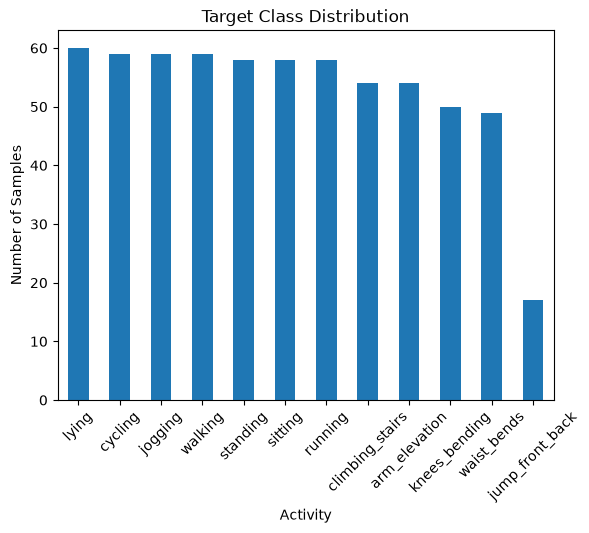

In [96]:
import matplotlib.pyplot as plt

train_clean['target'].value_counts().plot(kind='bar')

plt.xlabel('Activity')
plt.ylabel('Number of Samples')
plt.title('Target Class Distribution')
plt.xticks(rotation=45)
plt.show()

In [97]:
train_clean[feature_cols].describe()

,t000_chest_acc_x,t000_chest_acc_y,t000_chest_acc_z,t000_chest_ecg_1,t000_chest_ecg_2,t000_ankle_acc_x,t000_ankle_acc_y,t000_ankle_acc_z,t000_ankle_gyro_x,t000_ankle_gyro_y,...,t249_ankle_mag_z,t249_arm_acc_x,t249_arm_acc_y,t249_arm_acc_z,t249_arm_gyro_x,t249_arm_gyro_y,t249_arm_gyro_z,t249_arm_mag_x,t249_arm_mag_y,t249_arm_mag_z
count,532.0,535.0,535.0,531.0,530.0,531.0,533.0,529.0,530.0,528.0,...,533.0,529.0,530.0,531.0,529.0,531.0,531.0,530.0,531.0,530.0
mean,-7.164002,-0.299007,-0.96976,-0.111096,-0.235389,1.81546,-9.134142,-0.461017,0.197452,-0.541781,...,-3.943792,-3.762843,-7.548692,2.45897,-0.137978,-0.461131,0.383617,-1.658392,5.436496,-9.357949
std,13.923027,7.15852,10.420624,2.389184,2.471685,9.935686,12.916273,16.088786,1.072933,1.016202,...,41.018592,14.715914,14.676393,10.926976,1.304414,1.309876,1.176302,91.692191,67.379349,197.501452
min,-62.59614,-28.711166,-44.566949,-9.576251,-10.063279,-40.730788,-60.45,-65.991123,-3.955621,-4.9,...,-175.95673,-64.23,-66.33279,-41.22,-5.754318,-5.754625,-4.678907,-369.279493,-277.522662,-800.34533
25%,-9.763025,-1.5105,-3.7452,-0.223965,-0.191522,0.09978,-10.179,-4.2045,-0.17811,-0.81473,...,-2.5882,-6.5647,-9.681475,-0.0326,-0.65098,-0.87269,-0.008621,-6.402,-6.8105,-13.91075
50%,-8.71685,-0.69068,-0.92416,-0.066981,-0.058608,1.3737,-9.6072,0.43257,0.27551,-0.64259,...,-0.29787,-2.36,-7.76535,1.9423,-0.22941,-0.61191,0.43319,0.35624,0.35393,-0.71382
75%,-4.99125,1.23325,0.805925,0.1842,0.10884,3.09625,-7.2076,2.26,0.506027,-0.41839,...,1.5433,-0.31149,-2.691775,5.01545,0.25294,-0.070842,0.8028,6.080525,9.75565,6.85945
max,47.738853,27.98996,42.836928,9.614922,9.903974,44.860153,42.144149,64.752704,4.27057,3.827854,...,173.699097,57.466184,53.96587,45.544463,5.380114,4.864214,5.374413,372.319575,282.17622,788.4662


In [98]:
feature_std = train_clean[feature_cols].std()

print("Zero variance features:", (feature_std == 0).sum())

Zero variance features: 0


In [99]:
print("Duplicate feature columns:",
      train_clean[feature_cols].T.duplicated().sum())

Duplicate feature columns: 0


In [100]:
sample = train_clean[train_clean['target'] == 'lying'].iloc[0]

print(sample['id'])
print(sample['target'])

TR000079
lying


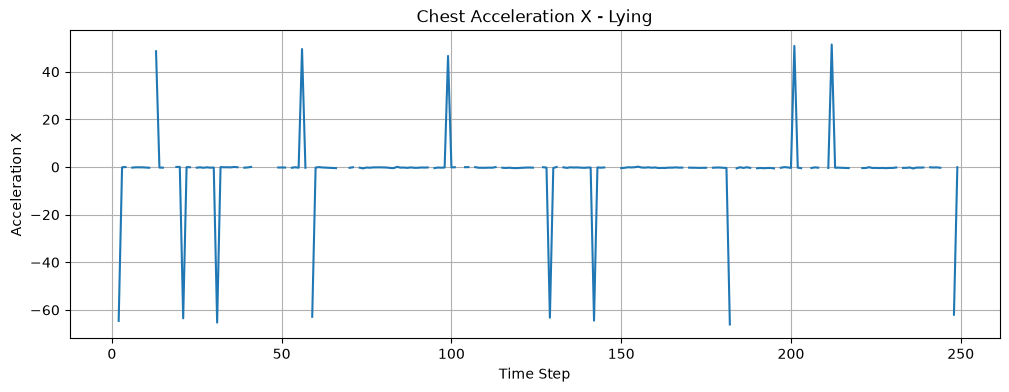

In [103]:
time_steps = range(250)
signal = []

for value in sample[signal_cols]:
    if pd.isna(value):
        signal.append(np.nan)
    else:
        signal.append(float(value))

plt.figure(figsize=(12, 4))
plt.plot(time_steps, signal)

plt.xlabel('Time Step')
plt.ylabel('Acceleration X')
plt.title('Chest Acceleration X - Lying')
plt.grid()
plt.show()

In [104]:
selected_cols = [
    f't{i:03d}_chest_acc_{axis}'
    for i in range(0, 250, 25)
    for axis in ['x', 'y', 'z']
]

corr = train_clean[selected_cols].corr()

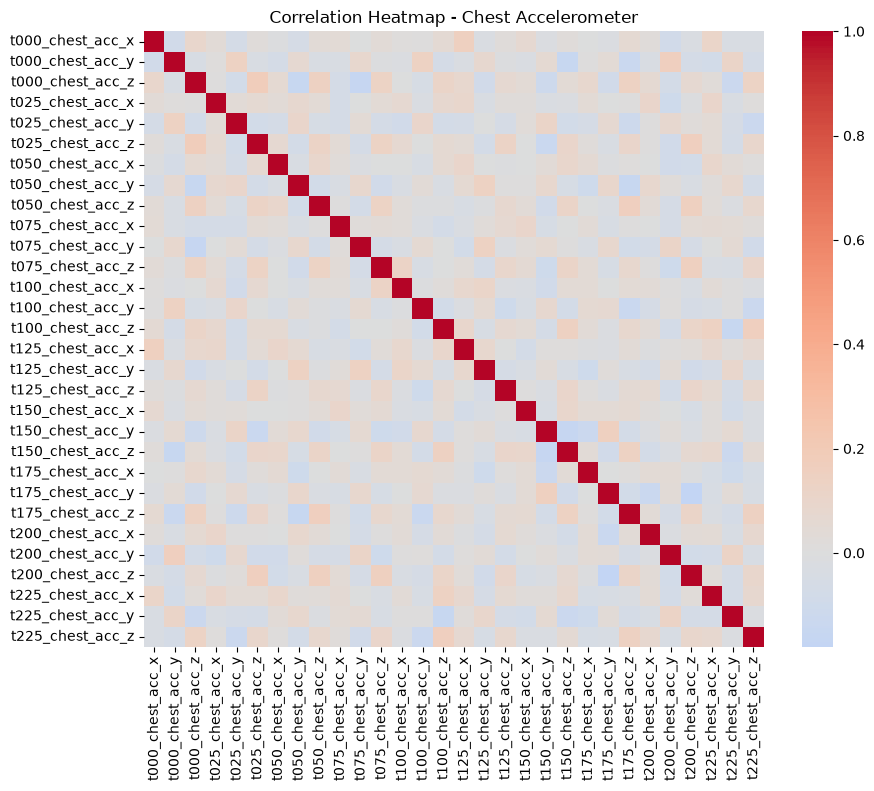

In [105]:
plt.figure(figsize=(10, 8))

sns.heatmap(corr, cmap='coolwarm', center=0)

plt.title('Correlation Heatmap - Chest Accelerometer')
plt.show()

In [106]:
print(train.columns[:10].tolist())
print(train.columns[-5:].tolist())

['id', 't000_chest_acc_x', 't000_chest_acc_y', 't000_chest_acc_z', 't000_chest_ecg_1', 't000_chest_ecg_2', 't000_ankle_acc_x', 't000_ankle_acc_y', 't000_ankle_acc_z', 't000_ankle_gyro_x']
['t249_arm_gyro_z', 't249_arm_mag_x', 't249_arm_mag_y', 't249_arm_mag_z', 'target']


In [107]:
print(train_clean['id'].head(15).tolist())

['TR000349', 'TR000004', 'TR000165', 'TR000592', 'TR000392', 'TR000445', 'TR000266', 'TR000227', 'TR000450', 'TR000318', 'TR000594', 'TR000581', 'TR000173', 'TR000069', 'TR000579']


In [108]:
print(train_clean.shape)
print(train_clean['target'].nunique())

(635, 5752)
12


In [109]:
import numpy as np

print("Train infinite values:",
      np.isinf(train_clean[feature_cols]).sum().sum())

print("Test infinite values:",
      np.isinf(test_clean[feature_cols]).sum().sum())

Train infinite values: 0
Test infinite values: 0


In [110]:
print("Train missing IDs:", train_clean['id'].isna().sum())
print("Train missing targets:", train_clean['target'].isna().sum())

print("Test missing IDs:", test_clean['id'].isna().sum())
print("Test duplicate IDs:", test_clean['id'].duplicated().sum())

Train missing IDs: 0
Train missing targets: 0
Test missing IDs: 0
Test duplicate IDs: 0


In [111]:
print("Same feature columns:",
      train_clean[feature_cols].columns.equals(
          test_clean[feature_cols].columns
      ))

Same feature columns: True


In [112]:
print("Unique target labels:")
print(sorted(train_clean['target'].unique()))

print("Missing target:", train_clean['target'].isna().sum())

Unique target labels:
['arm_elevation', 'climbing_stairs', 'cycling', 'jogging', 'jump_front_back', 'knees_bending', 'lying', 'running', 'sitting', 'standing', 'waist_bends', 'walking']
Missing target: 0


In [113]:
import os

os.makedirs("../data/processed", exist_ok=True)

train_clean.to_csv("../data/processed/train_clean.csv", index=False)
test_clean.to_csv("../data/processed/test_clean.csv", index=False)

print("Files saved successfully!")

Files saved successfully!
